# Checking the Checker: an AI audit layer for exam marking
**Taleemabad "Future of Education" Challenge — prototype notebook**

**Hypothesis H1:** at a fixed human review budget (e.g. 20% of scripts re-checked),
*risk-ranked* review catches more marking errors than *random* review.

**What this notebook does, step by step**
1. Load the public dataset (50 handwritten exam scripts, answer key, teacher marks).
2. Build the clean "true marks" (baseline) using the official key and verified fixes.
3. Turn PDF pages into images and separate the examiner's **red ink** from the student's ink.
4. Talk to local models through **Ollama** (nothing leaves the computer).
5. **Bake-off:** compare models and pipelines on a few scripts, then pick one by the numbers.
6. Read all scripts with the chosen pipeline (cached to disk).
7. **AI second reader:** estimate a mark for every answer (never used as the final mark).
8. **Plant errors** with a fixed random plan (made *before* detection and kept sealed).
9. **Audit:** consistency checks + AI disagreement -> one risk score per script.
10. **Evaluate H1:** random vs risk-ranked review at budgets of 5–50%.
11. **Real-world pilot:** run the audit on the dataset's *original* teacher records.
12. **H2 cost:** cost of the audit per script vs a human review.

Decisions behind every step are logged in `../decisions/`.

## 0. Install packages (run once)
PyMuPDF renders PDFs without extra Windows tools. Ollama must already be running (`ollama serve`
starts automatically on Windows after install).

In [1]:
# Run this once, then you can comment it out
%pip install pymupdf pillow numpy pandas requests matplotlib

Note: you may need to restart the kernel to use updated packages.


## 1. Imports and settings
All paths and model names live here, so they are easy to change.

In [2]:
import json
import time
import random
import base64
import re
import io
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import pymupdf  # PyMuPDF (renders PDF pages)
from PIL import Image, ImageFilter
import matplotlib.pyplot as plt

# ---- folders ----
DATA_DIR = Path("../data/A Dataset of Digitized Student Examination Papers,")
MARKED_PDF_DIR = DATA_DIR / "Corrected_Pdf"      # scripts marked by the teacher (our input)
OUT_DIR = Path("outputs")
PAGE_DIR = OUT_DIR / "pages"
CACHE_DIR = OUT_DIR / "cache"
for folder in [OUT_DIR, PAGE_DIR, CACHE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# ---- Ollama ----
OLLAMA_URL = "http://localhost:11434/api/chat"
VISION_MODELS = ["qwen3-vl:8b-instruct", "qwen3-vl:4b-instruct", "minicpm-v4.5"]   # instruct = no hidden "thinking" (see D-015)
OCR_MODEL = "glm-ocr"
STRUCTURE_MODEL = "qwen3-vl:4b-instruct"   # turns plain OCR text into JSON (pipeline B)

# ---- exam structure ----
MCQ_QUESTIONS = list(range(1, 21))    # 1 mark each
SA_QUESTIONS = list(range(21, 36))    # 2 marks each
MAX_MARK = {}
for q in MCQ_QUESTIONS:
    MAX_MARK[q] = 1
for q in SA_QUESTIONS:
    MAX_MARK[q] = 2

RENDER_DPI = 150
IMAGE_MAX_SIDE = 1400   # pages are shrunk to this before sending (faster, still readable)
SEED = 2026
print("Marked PDFs found:", len(list(MARKED_PDF_DIR.glob("*.pdf"))))

Marked PDFs found: 50


## 2. Load the dataset
We only use the anonymised files. **`Student_MCQ.csv` and `file.txt` are never loaded**: they contain
what look like real student names / IDs (see decision D-010).

In [3]:
questions_text = (DATA_DIR / "Question.txt").read_text(encoding="utf-8")
key_df = pd.read_csv(DATA_DIR / "answerkey.txt")
marks_df = pd.read_csv(DATA_DIR / "Teacher_manual_marks_Anonymized.csv")

# answer key as a simple dictionary: question number -> correct answer / key points
answer_key = {}
for _, row in key_df.iterrows():
    answer_key[int(row["Question_Number"])] = str(row["Correct_Answer"]).strip()

# question text for each question number (used by the AI second reader)
question_of = {}
for line in questions_text.splitlines():
    m = re.match(r"^(\d+)\.\s+(.*)", line.strip())
    if m:
        question_of[int(m.group(1))] = m.group(2)

students = [s for s in marks_df["Student_ID"]]
print(len(students), "students |", len(answer_key), "key entries")
marks_df.head(3)

50 students | 35 key entries


,Student_ID,Student_Name,MCQ mark,2 marks,total,1,2,3,4,5,...,26,27,28,29,30,31,32,33,34,35
0,Student_1,Anonymous_1,12,21.0,33.0,D,C,B,A,B,...,2.0,1.0,2.0,1.0,2,1.0,NaN,0.0,2.0,2.0
1,Student_2,Anonymous_2,10,13.0,23.0,A,A,A,A,B,...,NaN,NaN,2.0,1.0,NaN,NaN,NaN,2.0,NaN,1.5
2,Student_3,Anonymous_3,11,13.0,24.0,D,A,D,C,B,...,2.0,1.0,1.0,2.0,NaN,1.0,0,NaN,1.0,NaN


## 3. Clean baseline ("true marks")
Rules (decisions D-010 and D-012):
- MCQ truth = **official key** (Q1 = B only) applied to the student's recorded choice.
- Short answers = teacher's mark, with verified fixes (Student_11 Q34: 4 -> 2, a double count).
- Blank / `NC` / `NM` = 0 and "not answered".
- Students whose records are not yet verified against the page are tagged **uncertain**
  (results are reported with and without them).

In [4]:
UNCERTAIN = ["Student_2", "Student_8", "Student_12", "Student_25", "Student_26", "Student_29",
             "Student_32", "Student_34", "Student_35", "Student_38", "Student_41",
             "Student_46", "Student_48", "Student_49"]
VERIFIED_FIXES = {("Student_11", 34): 2.0}   # see ../data/baseline_fixes.csv

def read_sa_value(value):
    # returns (mark, answered?)
    text = str(value).strip()
    if text in ["", "nan", "NC", "NM"]:
        return 0.0, False
    return float(text), True

truth = {}        # truth[student][question] = true mark
answered = {}     # answered[student][question] = True / False
recorded = {}     # what the teacher actually recorded (original CSV), for the real-world pilot

for _, row in marks_df.iterrows():
    s = row["Student_ID"]
    truth[s] = {}
    answered[s] = {}
    recorded[s] = {"mcq_total": float(row["MCQ mark"]), "sa_total": float(row["2 marks"]),
                   "total": float(row["total"]), "sa": {}}
    for q in MCQ_QUESTIONS:
        choice = str(row[str(q)]).strip()
        answered[s][q] = choice not in ["", "nan"]
        truth[s][q] = 1.0 if choice == answer_key[q] else 0.0
    for q in SA_QUESTIONS:
        mark, was_answered = read_sa_value(row[str(q)])
        recorded[s]["sa"][q] = mark
        answered[s][q] = was_answered
        truth[s][q] = VERIFIED_FIXES.get((s, q), mark)

truth_total = {s: sum(truth[s].values()) for s in students}
print("Student_10 MCQ: recorded", recorded["Student_10"]["mcq_total"],
      "| true", sum(truth["Student_10"][q] for q in MCQ_QUESTIONS))
print("Student_11 Q34: recorded", recorded["Student_11"]["sa"][34], "| true", truth["Student_11"][34])

Student_10 MCQ: recorded 2.0 | true 8.0
Student_11 Q34: recorded 4.0 | true 2.0


## 4. Turn PDF pages into images
Each marked script (4–6 pages) becomes PNG images at 150 DPI. Done once, then reused.

In [5]:
def pdf_to_pages(student):
    pdf_path = MARKED_PDF_DIR / (student + ".pdf")
    pages = []
    doc = pymupdf.open(pdf_path)
    for i, page in enumerate(doc):
        out_path = PAGE_DIR / f"{student}_p{i+1}.png"
        if not out_path.exists():
            pix = page.get_pixmap(dpi=RENDER_DPI)
            pix.save(out_path)
        pages.append(out_path)
    doc.close()
    return pages

pages_of = {}
for s in students:
    pages_of[s] = pdf_to_pages(s)
print("Total pages:", sum(len(p) for p in pages_of.values()))

Total pages: 200


## 5. Separate the examiner's red ink from the student's ink
The examiner marks in **red**, students write in **blue/black**. A simple colour rule (HSV) makes two images:
- **student layer**: red removed (what the student wrote)
- **red layer**: student ink faded to light grey, red made bold (what the examiner wrote, still in place)

This is classic computer vision: cheap, explainable, no AI.

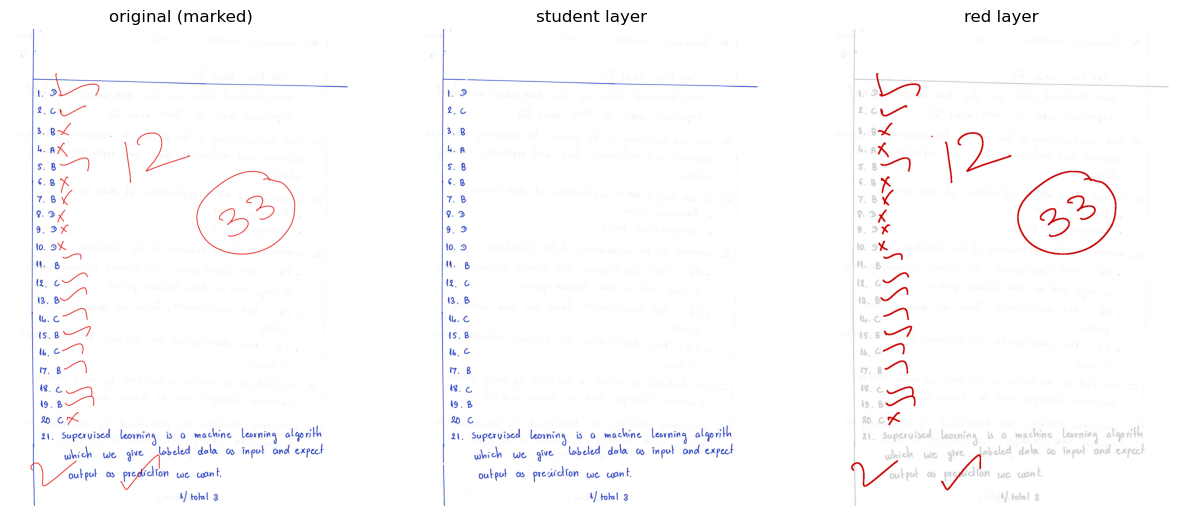

In [6]:
def red_mask(image):
    hsv = np.array(image.convert("HSV")).astype(int)
    hue, sat, val = hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]
    # PIL hue is 0..255, red sits at both ends of the circle
    is_red = ((hue <= 14) | (hue >= 235)) & (sat > 70) & (val > 60)
    mask = Image.fromarray((is_red * 255).astype(np.uint8))
    mask = mask.filter(ImageFilter.MaxFilter(3))   # thicken thin red strokes a little
    return np.array(mask) > 0

def student_layer(image):
    rgb = np.array(image.convert("RGB"))
    rgb[red_mask(image)] = [255, 255, 255]
    return Image.fromarray(rgb)

def red_layer(image):
    rgb = np.array(image.convert("RGB"))
    mask = red_mask(image)
    dark = rgb.mean(axis=2) < 180
    rgb[dark & ~mask] = [205, 205, 205]   # fade student ink, keep positions
    rgb[mask] = [200, 0, 0]               # bold red
    return Image.fromarray(rgb)

example = Image.open(pages_of["Student_1"][0])
fig, axes = plt.subplots(1, 3, figsize=(15, 7))
for ax, img, title in zip(axes, [example, student_layer(example), red_layer(example)],
                          ["original (marked)", "student layer", "red layer"]):
    ax.imshow(img); ax.set_title(title); ax.axis("off")
plt.show()

## 6. Helper: call a local model through Ollama
One function sends a prompt (and optionally an image) and returns the text plus the time taken.
Temperature 0 so results are repeatable. Every answer is cached on disk, so re-running the notebook is free.

In [7]:
def image_to_b64(image):
    image = image.convert("RGB")
    if max(image.size) > IMAGE_MAX_SIDE:
        image.thumbnail((IMAGE_MAX_SIDE, IMAGE_MAX_SIDE))
    buffer = io.BytesIO()
    image.save(buffer, format="PNG")
    return base64.b64encode(buffer.getvalue()).decode("utf-8")

def ask_model(model, prompt, image=None, want_json=True, cache_name=None):
    cache_file = None
    if cache_name:
        safe_model = model.replace(":", "_").replace("/", "_")
        cache_file = CACHE_DIR / safe_model / (cache_name + ".json")
        if cache_file.exists():
            cached = json.loads(cache_file.read_text(encoding="utf-8"))
            if cached.get("text", "").strip():     # never reuse an EMPTY answer (bug found in first run, D-015)
                return cached

    message = {"role": "user", "content": prompt}
    if image is not None:
        message["images"] = [image_to_b64(image)]
    body = {"model": model, "messages": [message], "stream": False, "think": False,
            "options": {"temperature": 0, "num_ctx": 16384, "num_predict": 3000}}
    if want_json:
        body["format"] = "json"

    start = time.time()
    reply = requests.post(OLLAMA_URL, json=body, timeout=900)
    if reply.status_code != 200 and "think" in reply.text:
        body.pop("think")                       # some models do not support the think switch
        reply = requests.post(OLLAMA_URL, json=body, timeout=900)
    reply.raise_for_status()
    seconds = time.time() - start
    data = reply.json()
    result = {"text": data["message"].get("content", ""),
              "thinking_chars": len(data["message"].get("thinking", "") or ""),
              "done_reason": data.get("done_reason"),
              "output_tokens": data.get("eval_count"),
              "seconds": seconds}

    if cache_file:
        cache_file.parent.mkdir(parents=True, exist_ok=True)
        cache_file.write_text(json.dumps(result), encoding="utf-8")
    return result

def parse_json(text):
    try:
        return json.loads(text)
    except Exception:
        match = re.search(r"\{.*\}", text, re.S)
        if match:
            try:
                return json.loads(match.group(0))
            except Exception:
                pass
    return {}

# quick check that Ollama is running
print(requests.get("http://localhost:11434/api/tags").json()["models"].__len__(), "models installed")

7 models installed


## 7. Prompts for reading a page
Three pipelines (decision D-011):
- **A — end-to-end:** the raw marked page goes to the VLM; it returns answers *and* red marks.
- **C — split layers (our main idea):** student layer -> answers; red layer -> examiner marks.
- **B — OCR specialist:** GLM-OCR transcribes text, then a small model structures it (no red marks).

In [8]:
PROMPT_FULL = (
    "This is a page of a handwritten exam answer script that was marked by a teacher in RED ink. "
    "The student wrote in blue or black ink. Questions 1-20 are multiple choice (the student writes a letter A-D). "
    "Questions 21-35 are short answers. Answers may appear in any order.\n"
    "For every question number visible on this page return an item with:\n"
    "  q: the question number (integer)\n"
    "  student_answer: for q 1-20 the single letter chosen; for q 21-35 the full answer text\n"
    "  red_symbol: 'tick', 'cross' or 'none' (the red mark next to this answer)\n"
    "  red_mark: the number the teacher wrote in red for this answer, or null if none\n"
    "Also return page_totals: a list of any circled totals written in red.\n"
    'Return JSON only: {"answers": [...], "page_totals": [...]}'
)

PROMPT_STUDENT = (
    "This is a page of a handwritten exam answer script. Questions 1-20 are multiple choice "
    "(the student writes a letter A-D). Questions 21-35 are short answers. Answers may appear in any order.\n"
    "For every question number visible return {q, student_answer}. For q 1-20 student_answer is one letter, "
    "for q 21-35 the full answer text exactly as written.\n"
    'Return JSON only: {"answers": [{"q": 1, "student_answer": "B"}, ...]}'
)

PROMPT_RED = (
    "This image shows ONLY the teacher's red marks on an exam page; the student's writing is faded to light grey "
    "so you can still see the question numbers. For every question number, report the red mark next to it:\n"
    "  red_symbol: 'tick', 'cross' or 'none'\n"
    "  red_mark: the number written in red for that answer, or null\n"
    "Also report page_totals: any circled totals.\n"
    'Return JSON only: {"answers": [{"q": 21, "red_symbol": "tick", "red_mark": 2}], "page_totals": [33]}'
)

PROMPT_STRUCTURE = (
    "Below is OCR text from a page of an exam answer script. Questions 1-20 are multiple choice (letters A-D), "
    "questions 21-35 are short answers. Split it into answers.\n"
    'Return JSON only: {"answers": [{"q": 1, "student_answer": "B"}, ...]}\n\nOCR TEXT:\n'
)

## 8. Read one script with a chosen pipeline
Reads every page, then merges pages into one record per question. If an answer continues over two pages
(like Student_11 Q34) the red marks of both parts are **added**, exactly as a teacher's double count would show up.

In [9]:
def first_letter(text):
    match = re.search(r"\b([ABCD])\b", str(text).upper())
    if match:
        return match.group(1)
    match = re.search(r"([ABCD])", str(text).upper())
    return match.group(1) if match else None

def to_number(value):
    try:
        return float(value)
    except Exception:
        return None

def read_page(pipeline, model, page_path):
    page = Image.open(page_path)
    name = page_path.stem
    answers, totals, seconds = [], [], 0.0

    if pipeline == "A":
        r = ask_model(model, PROMPT_FULL, page, cache_name=f"A_{name}")
        data = parse_json(r["text"]); seconds += r["seconds"]
        answers = data.get("answers", []); totals = data.get("page_totals", [])

    elif pipeline == "C":
        r1 = ask_model(model, PROMPT_STUDENT, student_layer(page), cache_name=f"Cs_{name}")
        r2 = ask_model(model, PROMPT_RED, red_layer(page), cache_name=f"Cr_{name}")
        seconds += r1["seconds"] + r2["seconds"]
        student_part = parse_json(r1["text"]).get("answers", [])
        red_data = parse_json(r2["text"])
        red_part = {}
        for item in red_data.get("answers", []):
            q = to_number(item.get("q"))
            if q is not None:
                red_part[int(q)] = item
        for item in student_part:
            q = to_number(item.get("q"))
            if q is None:
                continue
            merged = dict(item)
            merged.update({k: v for k, v in red_part.get(int(q), {}).items() if k != "q"})
            answers.append(merged)
        # red marks for questions the student layer did NOT find on this page are dropped:
        # they are guesses and caused double counting in the bake-off (bug found, decision D-016)
        totals = red_data.get("page_totals", [])

    elif pipeline == "B":
        r1 = ask_model(OCR_MODEL, "Text Recognition:", page, want_json=False, cache_name=f"Bo_{name}")
        r2 = ask_model(STRUCTURE_MODEL, PROMPT_STRUCTURE + r1["text"], None, cache_name=f"Bs_{name}")
        seconds += r1["seconds"] + r2["seconds"]
        answers = parse_json(r2["text"]).get("answers", [])

    return answers, totals, seconds

def read_script(pipeline, model, student):
    record = {}      # question -> {"text": ..., "letter": ..., "symbols": [...], "marks": [...]}
    all_totals, total_seconds = [], 0.0
    for page_path in pages_of[student]:
        answers, totals, seconds = read_page(pipeline, model, page_path)
        total_seconds += seconds
        all_totals += totals if isinstance(totals, list) else [totals]
        for item in answers:
            q = to_number(item.get("q"))
            if q is None or int(q) not in MAX_MARK:
                continue
            q = int(q)
            if q not in record:
                record[q] = {"text": "", "letter": None, "symbols": [], "marks": []}
            text = str(item.get("student_answer", "") or "")
            record[q]["text"] = (record[q]["text"] + " " + text).strip()
            if q in MCQ_QUESTIONS and record[q]["letter"] is None:
                record[q]["letter"] = first_letter(text)
            symbol = item.get("red_symbol")
            if symbol:
                record[q]["symbols"].append(str(symbol).lower())
            mark = to_number(item.get("red_mark"))
            if mark is not None:
                record[q]["marks"].append(mark)
    return record, all_totals, total_seconds

## 8b. Smoke test: does each model answer at all? (one page, ~1–3 minutes)
Run this before the bake-off. For every model/pipeline it reads ONE page (Student_1, page 1) and prints how long it
took and the first part of the raw answer. If a model fails here (out of memory, bad JSON, empty answer),
fix it before the long run. Results are cached, so the bake-off reuses them.

In [10]:
test_page = pages_of["Student_1"][0]
for pipeline, model in [("A", m) for m in VISION_MODELS] + [("C", m) for m in VISION_MODELS] + [("B", OCR_MODEL)]:
    try:
        answers, totals, sec = read_page(pipeline, model, test_page)
        questions = sorted(int(to_number(a.get("q"))) for a in answers if to_number(a.get("q")) is not None)
        print(f"{pipeline} {model:22s} | {sec:6.1f}s | {len(answers)} items | questions: {questions[:25]} | totals: {totals}")
        if not answers:   # show why: raw text, hidden thinking, stop reason
            safe = model.replace(":", "_").replace("/", "_")
            for f in sorted((CACHE_DIR / safe).glob(f"*{test_page.stem}.json")):
                d = json.loads(f.read_text(encoding="utf-8"))
                print("    ", f.name, "| done:", d.get("done_reason"), "| tokens:", d.get("output_tokens"),
                      "| thinking chars:", d.get("thinking_chars"), "| text:", repr(d.get("text", "")[:200]))
    except Exception as error:
        print(f"{pipeline} {model:22s} | FAILED: {error}")

A qwen3-vl:8b-instruct   |   17.7s | 21 items | questions: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21] | totals: [33]
A qwen3-vl:4b-instruct   |   22.9s | 21 items | questions: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21] | totals: [33]
A minicpm-v4.5           |   54.9s | 21 items | questions: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21] | totals: ['33']


C qwen3-vl:8b-instruct   |   19.2s | 21 items | questions: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21] | totals: [33]


C qwen3-vl:4b-instruct   |   35.4s | 21 items | questions: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21] | totals: [33]


C minicpm-v4.5           |   71.8s | 21 items | questions: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21] | totals: [33]
B glm-ocr                |   79.5s | 20 items | questions: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20] | totals: []


## 9. Bake-off: which model and pipeline reads these scripts best?
Five scripts (Students 1, 5, 14, 10, 11). Ground truth comes from the dataset itself:
- **coverage:** share of answered questions the model found
- **MCQ letter accuracy:** model's letter vs recorded choice
- **red-mark accuracy (short answers):** model's red number vs the teacher's recorded mark
  (Student_11 Q34 excluded: it is the double-count case)
- **seconds per page**

Pipeline B cannot read red marks, so it is only scored on coverage and letters.
This takes a while the first time; everything is cached.

In [11]:
BAKEOFF_STUDENTS = ["Student_1", "Student_5", "Student_14", "Student_10", "Student_11"]
CONFIGS = [("A", m) for m in VISION_MODELS] + [("C", m) for m in VISION_MODELS] + [("B", OCR_MODEL)]

def score_reading(record, student):
    row = marks_df[marks_df["Student_ID"] == student].iloc[0]
    found = hit_letters = n_letters = hit_marks = n_marks = 0
    n_answered = sum(1 for q in MAX_MARK if answered[student][q])
    for q in MAX_MARK:
        if not answered[student][q]:
            continue
        if q in record:
            found += 1
        if q in MCQ_QUESTIONS:
            n_letters += 1
            if q in record and record[q]["letter"] == str(row[str(q)]).strip():
                hit_letters += 1
        else:
            if student == "Student_11" and q == 34:
                continue
            n_marks += 1
            if q in record and record[q]["marks"] and abs(sum(record[q]["marks"]) - recorded[student]["sa"][q]) < 0.01:
                hit_marks += 1
    return found, n_answered, hit_letters, n_letters, hit_marks, n_marks

bake_rows = []
for pipeline, model in CONFIGS:
    totals = np.zeros(6)
    seconds = 0.0
    n_pages = 0
    try:
        for s in BAKEOFF_STUDENTS:
            record, _, sec = read_script(pipeline, model, s)
            totals += np.array(score_reading(record, s))
            seconds += sec
            n_pages += len(pages_of[s])
    except Exception as error:
        print("FAILED", pipeline, model, "->", error)
        continue
    found, n_ans, hl, nl, hm, nm = totals
    bake_rows.append({"pipeline": pipeline, "model": model,
                      "coverage": round(found / n_ans, 3),
                      "mcq_letter_acc": round(hl / nl, 3),
                      "red_mark_acc": round(hm / nm, 3) if pipeline != "B" else None,
                      "sec_per_page": round(seconds / n_pages, 1)})
    print(bake_rows[-1])

bakeoff = pd.DataFrame(bake_rows)
bakeoff.to_csv(OUT_DIR / "bakeoff_results.csv", index=False)
bakeoff

{'pipeline': 'A', 'model': 'qwen3-vl:8b-instruct', 'coverage': np.float64(0.957), 'mcq_letter_acc': np.float64(1.0), 'red_mark_acc': np.float64(0.129), 'sec_per_page': 8.7}


{'pipeline': 'A', 'model': 'qwen3-vl:4b-instruct', 'coverage': np.float64(0.583), 'mcq_letter_acc': np.float64(0.4), 'red_mark_acc': np.float64(0.113), 'sec_per_page': 15.6}
{'pipeline': 'A', 'model': 'minicpm-v4.5', 'coverage': np.float64(0.969), 'mcq_letter_acc': np.float64(0.97), 'red_mark_acc': np.float64(0.161), 'sec_per_page': 10.9}


{'pipeline': 'C', 'model': 'qwen3-vl:8b-instruct', 'coverage': np.float64(0.951), 'mcq_letter_acc': np.float64(0.99), 'red_mark_acc': np.float64(0.274), 'sec_per_page': 12.2}


{'pipeline': 'C', 'model': 'qwen3-vl:4b-instruct', 'coverage': np.float64(0.939), 'mcq_letter_acc': np.float64(0.99), 'red_mark_acc': np.float64(0.161), 'sec_per_page': 28.8}


{'pipeline': 'C', 'model': 'minicpm-v4.5', 'coverage': np.float64(0.982), 'mcq_letter_acc': np.float64(0.99), 'red_mark_acc': np.float64(0.097), 'sec_per_page': 13.4}
{'pipeline': 'B', 'model': 'glm-ocr', 'coverage': np.float64(0.595), 'mcq_letter_acc': np.float64(0.97), 'red_mark_acc': None, 'sec_per_page': 27.8}


,pipeline,model,coverage,mcq_letter_acc,red_mark_acc,sec_per_page
0,A,qwen3-vl:8b-instruct,0.957,1.00,0.129,8.7
1,A,qwen3-vl:4b-instruct,0.583,0.40,0.113,15.6
2,A,minicpm-v4.5,0.969,0.97,0.161,10.9
3,C,qwen3-vl:8b-instruct,0.951,0.99,0.274,12.2
4,C,qwen3-vl:4b-instruct,0.939,0.99,0.161,28.8
5,C,minicpm-v4.5,0.982,0.99,0.097,13.4
6,B,glm-ocr,0.595,0.97,NaN,27.8


## 10. Choose the pipeline (decided by the numbers above)
Rule: highest `mcq_letter_acc + red_mark_acc`; if two are within 0.02, take the faster one.
You can override by hand; any override must be logged in `../decisions/`.

In [12]:
candidates = bakeoff.dropna(subset=["red_mark_acc"]).copy()
candidates["score"] = candidates["mcq_letter_acc"] + candidates["red_mark_acc"]
candidates = candidates.sort_values(["score", "sec_per_page"], ascending=[False, True])
best = candidates.iloc[0]
close = candidates[candidates["score"] >= best["score"] - 0.02].sort_values("sec_per_page")
chosen = close.iloc[0]
CHOSEN_PIPELINE, CHOSEN_MODEL = chosen["pipeline"], chosen["model"]

# how often the chosen reader gets a red mark wrong: used to add realistic noise in the simulation
RED_READ_ERROR = 1 - float(chosen["red_mark_acc"])
print("Chosen:", CHOSEN_PIPELINE, CHOSEN_MODEL, "| red-mark reading error rate:", round(RED_READ_ERROR, 3))

Chosen: C qwen3-vl:8b-instruct | red-mark reading error rate: 0.726


## 11. Read all 50 scripts with the chosen pipeline
Long run the first time (roughly 200 pages). Cached, so it can be stopped and resumed.
`N_SCRIPTS` lets you try a smaller run first.

In [13]:
N_SCRIPTS = len(students)     # e.g. set to 10 for a quick test
readings = {}
seconds_per_script = {}
for i, s in enumerate(students[:N_SCRIPTS]):
    record, totals, sec = read_script(CHOSEN_PIPELINE, CHOSEN_MODEL, s)
    readings[s] = {"record": record, "totals": totals}
    seconds_per_script[s] = sec
    print(f"{i+1}/{N_SCRIPTS} {s}: {len(record)} questions found, {sec:.0f}s")
students_run = list(readings.keys())

1/50 Student_1: 32 questions found, 63s


2/50 Student_2: 29 questions found, 551s


3/50 Student_3: 32 questions found, 181s


4/50 Student_4: 35 questions found, 55s


5/50 Student_5: 27 questions found, 39s


6/50 Student_6: 27 questions found, 41s


... (40 outputs left out)

47/50 Student_47: 27 questions found, 49s


48/50 Student_48: 25 questions found, 39s


49/50 Student_49: 28 questions found, 41s


50/50 Student_50: 35 questions found, 63s


## 12. AI second reader: an independent mark estimate for every answer
- **MCQ:** 1 if the letter the model read matches the official key, else 0.
- **Short answers:** the model grades the *text it read* against the key points (0, 0.5, 1, 1.5, 2).

These estimates are **never used as marks**. They only feed the risk score.

In [14]:
GRADER_MODEL = CHOSEN_MODEL if CHOSEN_PIPELINE != "B" else "qwen3-vl:8b-instruct"

def grade_prompt(q, answer_text):
    return ("You are a second reader checking an exam answer. Be fair and follow the key points.\n"
            f"Question: {question_of.get(q, '')}\n"
            f"Key points (model answer): {answer_key[q]}\n"
            f"Student answer (read from handwriting, may contain reading mistakes): {answer_text}\n"
            "Maximum mark: 2. Allowed marks: 0, 0.5, 1, 1.5, 2.\n"
            'Return JSON only: {"mark": <number>, "reason": "<one short sentence>"}')

ai_mark = {}
for s in students_run:
    ai_mark[s] = {}
    record = readings[s]["record"]
    for q in MCQ_QUESTIONS:
        letter = record.get(q, {}).get("letter")
        ai_mark[s][q] = None if letter is None else (1.0 if letter == answer_key[q] else 0.0)
    for q in SA_QUESTIONS:
        text = record.get(q, {}).get("text", "")
        if not text:
            ai_mark[s][q] = None        # model found no answer
            continue
        r = ask_model(GRADER_MODEL, grade_prompt(q, text), None, cache_name=f"grade_{s}_q{q}")
        value = to_number(parse_json(r["text"]).get("mark"))
        ai_mark[s][q] = None if value is None else min(max(value, 0.0), 2.0)

# how close is the AI second reader to the true marks? (honest check of the reader itself)
diffs = [abs(ai_mark[s][q] - truth[s][q]) for s in students_run for q in MAX_MARK
         if ai_mark[s][q] is not None and answered[s][q]]
print("AI second reader | mean abs difference from truth:", round(float(np.mean(diffs)), 3),
      "| exact agreement:", round(float(np.mean([d < 0.01 for d in diffs])), 3))

AI second reader | mean abs difference from truth: 0.372 | exact agreement: 0.702


## 13. Plant marking errors (random plan, made BEFORE the audit and kept sealed)
We simulate an examiner's record of every script in two places:
- **page marks** (what the examiner wrote on the script)
- **award list** (what was copied into the result system), plus the total

Starting from the clean truth, a fixed random plan plants errors:

| type | what happens | who can catch it |
|---|---|---|
| C1 copy error | award list differs from the page | consistency check |
| C2 total error | total is not the sum of the marks | consistency check |
| C3 over maximum | mark above the question maximum (like Student_11) | consistency check |
| J1 under-credit | correct answer given low marks on page *and* list | AI second reader only |
| J2 over-credit | wrong answer given marks on page *and* list | AI second reader only |
| J3 unmarked | answered question left with no mark | consistency check (if the answer is found) |

The plan is saved to `planted_errors_SEALED.json`. The audit in step 14 never reads it; only the
evaluation in step 15 does. The page marks the audit "sees" also get realistic **reading noise** at the
error rate measured in the bake-off.

In [15]:
ERROR_TYPES = ["C1", "C2", "C3", "J1", "J2", "J3"]
P_ONE_ERROR = 0.30     # share of scripts with one error
P_TWO_ERRORS = 0.10    # share with two errors

def make_error_plan(seed):
    rng = random.Random(seed)
    plan = {}
    for s in students_run:
        roll = rng.random()
        n = 2 if roll < P_TWO_ERRORS else (1 if roll < P_TWO_ERRORS + P_ONE_ERROR else 0)
        plan[s] = []
        for _ in range(n):
            error_type = rng.choice(ERROR_TYPES)
            if error_type == "J1":
                options = [q for q in MAX_MARK if truth[s][q] == MAX_MARK[q]]
            elif error_type == "J2":
                options = [q for q in MAX_MARK if answered[s][q] and truth[s][q] == 0]
            elif error_type == "J3":
                options = [q for q in MAX_MARK if answered[s][q] and truth[s][q] > 0]
            else:
                options = list(MAX_MARK)
            if not options:
                continue
            plan[s].append({"type": error_type, "q": rng.choice(options)})
    return plan

def allowed_values(q):
    # MCQ marks are 0 or 1; short answers go in half marks up to 2
    return [0.0, 1.0] if q in MCQ_QUESTIONS else [0.0, 0.5, 1.0, 1.5, 2.0]

def build_examiner_record(plan, seed):
    rng = random.Random(seed + 1)
    page, award = {}, {}
    award_total = {}
    for s in students_run:
        page[s] = dict(truth[s])
        award[s] = dict(truth[s])
        total_shift = 0.0
        for err in plan[s]:
            q, t, top = err["q"], err["type"], MAX_MARK[err["q"]]
            if t == "C1":
                award[s][q] = rng.choice([v for v in allowed_values(q) if v != page[s][q]])
            elif t == "C2":
                total_shift += rng.choice([-2, -1, 1, 2])
            elif t == "C3":
                award[s][q] = page[s][q] = top * 2
            elif t == "J1":
                award[s][q] = page[s][q] = 0.0
            elif t == "J2":
                award[s][q] = page[s][q] = top
            elif t == "J3":
                award[s][q] = 0.0
                page[s][q] = None          # no mark written on the page
        award_total[s] = sum(award[s].values()) + total_shift
    return page, award, award_total

def add_reading_noise(page, seed):
    rng = random.Random(seed + 2)
    seen = {}
    for s in page:
        seen[s] = {}
        for q, value in page[s].items():
            if value is not None and rng.random() < RED_READ_ERROR:
                seen[s][q] = rng.choice([v for v in allowed_values(q) + [None] if v != value])
            else:
                seen[s][q] = value
    return seen

plan = make_error_plan(SEED)
(OUT_DIR / "planted_errors_SEALED.json").write_text(json.dumps(plan, indent=1))
page_marks, award_list, award_totals = build_examiner_record(plan, SEED)
page_seen = add_reading_noise(page_marks, SEED)
print("Scripts with planted errors:", sum(1 for s in plan if plan[s]), "of", len(plan),
      "| errors:", sum(len(v) for v in plan.values()))

Scripts with planted errors: 10 of 50 | errors: 13


## 14. The audit: one risk score per script
Two kinds of evidence (decision D-006):

**Consistency checks (no AI judgement, fully explainable)**
- a mark above the question maximum -> strong flag
- the total is not the sum of the marks -> strong flag
- award list differs from the page mark -> flag
- an answer was found on the page but has no mark -> flag

**AI disagreement**
- sum over questions of |AI estimate − recorded mark|

`risk = 10 × strong flags + 3 × flags + AI disagreement`. The audit only uses what a real board would have:
the page as read by the model, the award list, and the AI estimates. It never looks at the plan or the truth.

In [16]:
W_STRONG, W_FLAG = 10, 3

def audit_script(s, page_view, award, total, ai):
    strong, flags, reasons = 0, 0, []
    for q in MAX_MARK:
        if award[q] > MAX_MARK[q]:
            strong += 1; reasons.append(f"Q{q}: {award[q]} > max {MAX_MARK[q]}")
        seen = page_view.get(q)
        if seen is not None and abs(seen - award[q]) > 0.01:
            flags += 1; reasons.append(f"Q{q}: page {seen} vs list {award[q]}")
        found_answer = q in readings[s]["record"]
        if found_answer and seen is None:
            flags += 1; reasons.append(f"Q{q}: answered but unmarked")
    if abs(sum(award.values()) - total) > 0.01:
        strong += 1; reasons.append(f"total {total} != sum {sum(award.values())}")
    disagreement = 0.0
    for q in MAX_MARK:
        if ai[q] is not None:
            disagreement += abs(ai[q] - min(award[q], MAX_MARK[q]))
    risk = W_STRONG * strong + W_FLAG * flags + disagreement
    return risk, reasons

risk, reasons = {}, {}
for s in students_run:
    risk[s], reasons[s] = audit_script(s, page_seen[s], award_list[s], award_totals[s], ai_mark[s])

ranking = sorted(students_run, key=lambda s: risk[s], reverse=True)
pd.DataFrame([{"student": s, "risk": round(risk[s], 2), "planted": plan[s], "reasons": reasons[s][:3]}
              for s in ranking[:10]])

,student,risk,planted,reasons
0,Student_11,107.5,[],"[Q1: answered but unmarked, Q2: page 0.0 vs li..."
1,Student_42,101.0,[],"[Q1: page 1.0 vs list 0.0, Q2: page 0.0 vs lis..."
2,Student_30,99.5,"[{'type': 'J3', 'q': 20}, {'type': 'C3', 'q': ...","[Q1: page 1.0 vs list 0.0, Q2: page 0.0 vs lis..."
3,Student_14,99.0,"[{'type': 'C1', 'q': 8}, {'type': 'C3', 'q': 7}]","[Q1: page 1.0 vs list 0.0, Q2: page 1.0 vs lis..."
4,Student_8,98.0,[],"[Q1: answered but unmarked, Q2: answered but u..."
5,Student_31,97.5,[],"[Q2: page 0.0 vs list 1.0, Q3: answered but un..."
6,Student_49,96.0,"[{'type': 'C2', 'q': 8}]","[Q1: answered but unmarked, Q4: answered but u..."
7,Student_25,95.5,"[{'type': 'C3', 'q': 6}, {'type': 'J2', 'q': 22}]","[Q1: answered but unmarked, Q2: page 0.0 vs li..."
8,Student_39,94.5,[],"[Q1: answered but unmarked, Q3: page 1.0 vs li..."
9,Student_44,94.0,[],"[Q2: page 0.0 vs list 1.0, Q3: answered but un..."


## 15. Evaluate H1: random review vs risk-ranked review
For each budget (share of scripts a human re-checks), we measure **error recall** = share of planted
errors that land in reviewed scripts.
- **Random:** average of 2,000 random orders (with a 95% range).
- **Risk-ranked:** review the highest-risk scripts first.
- 95% confidence interval for ranked review by bootstrap over scripts.
Reported for all scripts and **without the uncertain students** (sensitivity check).

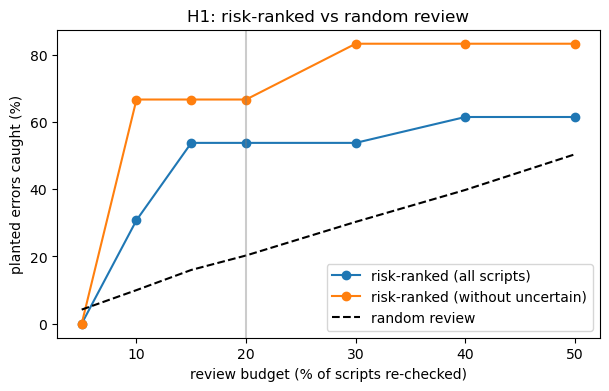

,set,budget,random_recall,random_95,ranked_recall,ranked_95
0,all scripts,0.05,0.042,"(0.0, 0.15)",0.000,"(0.0, 0.29)"
1,all scripts,0.10,0.100,"(0.0, 0.31)",0.308,"(0.0, 0.5)"
2,all scripts,0.15,0.160,"(0.0, 0.38)",0.538,"(0.08, 0.56)"
3,all scripts,0.20,0.203,"(0.0, 0.46)",0.538,"(0.1, 0.62)"
4,all scripts,0.30,0.303,"(0.08, 0.54)",0.538,"(0.15, 0.62)"
5,all scripts,0.40,0.398,"(0.15, 0.69)",0.615,"(0.15, 0.67)"
6,all scripts,0.50,0.504,"(0.23, 0.77)",0.615,"(0.2, 0.69)"
0,without uncertain,0.05,0.055,"(0.0, 0.33)",0.000,"(0.0, 0.67)"
1,without uncertain,0.10,0.109,"(0.0, 0.5)",0.667,"(0.0, 1.0)"
2,without uncertain,0.15,0.131,"(0.0, 0.5)",0.667,"(0.0, 1.0)"


In [17]:
BUDGETS = [0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50]

def recall_for_order(order, budget, plan_used):
    k = max(1, round(budget * len(order)))
    reviewed = set(order[:k])
    total_errors = sum(len(plan_used[s]) for s in order)
    caught = sum(len(plan_used[s]) for s in reviewed)
    return caught / total_errors if total_errors else float("nan")

def evaluate(script_list, label):
    rng = random.Random(SEED + 7)
    ranked_order = sorted(script_list, key=lambda s: risk[s], reverse=True)
    rows = []
    for b in BUDGETS:
        random_recalls = []
        for _ in range(2000):
            order = script_list[:]
            rng.shuffle(order)
            random_recalls.append(recall_for_order(order, b, plan))
        boot = []
        for _ in range(1000):
            sample = [rng.choice(script_list) for _ in script_list]
            sample_order = sorted(sample, key=lambda s: risk[s], reverse=True)
            boot.append(recall_for_order(sample_order, b, plan))
        rows.append({"set": label, "budget": b,
                     "random_recall": round(float(np.mean(random_recalls)), 3),
                     "random_95": (round(float(np.percentile(random_recalls, 2.5)), 2),
                                   round(float(np.percentile(random_recalls, 97.5)), 2)),
                     "ranked_recall": round(recall_for_order(ranked_order, b, plan), 3),
                     "ranked_95": (round(float(np.nanpercentile(boot, 2.5)), 2),
                                   round(float(np.nanpercentile(boot, 97.5)), 2))})
    return pd.DataFrame(rows)

results_all = evaluate(students_run, "all scripts")
results_certain = evaluate([s for s in students_run if s not in UNCERTAIN], "without uncertain")
h1 = pd.concat([results_all, results_certain])
h1.to_csv(OUT_DIR / "h1_results.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 4))
for label, frame in h1.groupby("set"):
    ax.plot(frame["budget"] * 100, frame["ranked_recall"] * 100, marker="o", label=f"risk-ranked ({label})")
ax.plot(results_all["budget"] * 100, results_all["random_recall"] * 100, "k--", label="random review")
ax.axvline(20, color="grey", alpha=0.4)
ax.set_xlabel("review budget (% of scripts re-checked)"); ax.set_ylabel("planted errors caught (%)")
ax.set_title("H1: risk-ranked vs random review"); ax.legend(); plt.show()
h1

## 15b. Recall by error type (where does each signal help?)
At the 20% budget, which planted error types were caught by ranked review?
We expect consistency errors (C1–C3) to be caught almost always, and judgement errors (J1, J2) to depend on the AI reader.

In [18]:
k = round(0.20 * len(students_run))
top = set(ranking[:k])
by_type = {}
for s in students_run:
    for err in plan[s]:
        t = err["type"]
        by_type.setdefault(t, [0, 0])
        by_type[t][1] += 1
        if s in top:
            by_type[t][0] += 1
pd.DataFrame([{"type": t, "caught": c, "planted": n, "recall": round(c / n, 2)} for t, (c, n) in sorted(by_type.items())])

,type,caught,planted,recall
0,C1,1,1,1.00
1,C2,1,1,1.00
2,C3,3,4,0.75
3,J1,0,1,0.00
4,J2,1,5,0.20
5,J3,1,1,1.00


## 15c. Repeat with 30 different random error plans (robustness)
One plan plants only ~13 errors, so one run is noisy. Here we plant errors 30 times with different seeds
(same rules), redo the audit each time, and average. This tells us whether the H1 result is stable or luck.

In [19]:
N_PLANS = 30
repeat_rows = []
for plan_seed in range(100, 100 + N_PLANS):
    plan_i = make_error_plan(plan_seed)
    page_i, award_i, total_i = build_examiner_record(plan_i, plan_seed)
    seen_i = add_reading_noise(page_i, plan_seed)
    risk_i = {s: audit_script(s, seen_i[s], award_i[s], total_i[s], ai_mark[s])[0] for s in students_run}
    order_i = sorted(students_run, key=lambda s: risk_i[s], reverse=True)
    n_errors = sum(len(v) for v in plan_i.values())
    for b in BUDGETS:
        k = max(1, round(b * len(order_i)))
        caught = sum(len(plan_i[s]) for s in order_i[:k])
        repeat_rows.append({"plan": plan_seed, "budget": b,
                            "ranked_recall": caught / n_errors if n_errors else np.nan,
                            "random_expected": k / len(order_i)})

repeat = pd.DataFrame(repeat_rows)
robust = repeat.groupby("budget").agg(ranked_mean=("ranked_recall", "mean"),
                                      ranked_low=("ranked_recall", lambda x: np.percentile(x, 2.5)),
                                      ranked_high=("ranked_recall", lambda x: np.percentile(x, 97.5)),
                                      random_expected=("random_expected", "mean")).round(3)
robust.to_csv(OUT_DIR / "h1_robustness_30_plans.csv")
robust

,ranked_mean,ranked_low,ranked_high,random_expected
budget,,,,
0.05,0.087,0.025,0.193,0.04
0.10,0.183,0.067,0.306,0.10
0.15,0.263,0.138,0.410,0.16
0.20,0.301,0.167,0.479,0.20
0.30,0.421,0.276,0.570,0.30
0.40,0.528,0.368,0.659,0.40
0.50,0.613,0.461,0.765,0.50


## 16. Real-world pilot: audit the dataset's ORIGINAL teacher records (nothing planted)
Here the record is what the teacher really recorded, and the page is the real marked page as read by the model.
Question: do the **confirmed real errors** (Student_10 under-marked by ~6, Student_11 double count)
rank near the top? These errors existed in the dataset before we touched it (decision D-012).

In [20]:
pilot = []
for s in students_run:
    rec = recorded[s]
    record = readings[s]["record"]
    strong, flags, why = 0, 0, []
    for q in SA_QUESTIONS:
        if rec["sa"][q] > MAX_MARK[q]:
            strong += 1; why.append(f"Q{q}: {rec['sa'][q]} > max 2")
    if abs(sum(rec["sa"].values()) - rec["sa_total"]) > 0.01:
        strong += 1; why.append("short-answer section total does not add up")
    if abs(rec["mcq_total"] + rec["sa_total"] - rec["total"]) > 0.01:
        strong += 1; why.append("grand total does not add up")
    ticks = sum(1 for q in MCQ_QUESTIONS if q in record and "tick" in record[q]["symbols"])
    if ticks and abs(ticks - rec["mcq_total"]) > 0.01:
        flags += 1; why.append(f"MCQ ticks on page {ticks} vs recorded {rec['mcq_total']}")
    ai_mcq = sum(v for q, v in ai_mark[s].items() if q in MCQ_QUESTIONS and v is not None)
    disagreement = abs(ai_mcq - rec["mcq_total"])
    for q in SA_QUESTIONS:
        if ai_mark[s][q] is not None:
            disagreement += abs(ai_mark[s][q] - min(rec["sa"][q], 2))
    pilot.append({"student": s, "risk": round(W_STRONG * strong + W_FLAG * flags + disagreement, 2),
                  "ai_mcq": ai_mcq, "recorded_mcq": rec["mcq_total"], "reasons": why})

pilot_df = pd.DataFrame(pilot).sort_values("risk", ascending=False).reset_index(drop=True)
pilot_df["rank"] = pilot_df.index + 1
pilot_df.to_csv(OUT_DIR / "real_world_pilot.csv", index=False)
for s in ["Student_10", "Student_11"]:
    if s in list(pilot_df["student"]):
        r = pilot_df[pilot_df["student"] == s].iloc[0]
        print(f"{s}: rank {r['rank']} of {len(pilot_df)} | risk {r['risk']} | {r['reasons']}")
pilot_df.head(10)

Student_10: rank 13 of 50 | risk 15.5 | []
Student_11: rank 1 of 50 | risk 27.5 | ['Q34: 4.0 > max 2']


,student,risk,ai_mcq,recorded_mcq,reasons,rank
0,Student_11,27.5,10.0,10.0,[Q34: 4.0 > max 2],1
1,Student_12,24.5,13.0,12.0,[short-answer section total does not add up],2
2,Student_31,23.5,13.0,14.0,[MCQ ticks on page 13 vs recorded 14.0],3
3,Student_17,23.0,9.0,14.0,[MCQ ticks on page 2 vs recorded 14.0],4
4,Student_42,21.0,13.0,14.0,[MCQ ticks on page 12 vs recorded 14.0],5
5,Student_39,20.5,5.0,6.0,[MCQ ticks on page 8 vs recorded 6.0],6
6,Student_50,20.0,12.0,13.0,[MCQ ticks on page 1 vs recorded 13.0],7
7,Student_30,19.5,11.0,13.0,[MCQ ticks on page 2 vs recorded 13.0],8
8,Student_29,18.5,13.0,16.0,[MCQ ticks on page 17 vs recorded 16.0],9
9,Student_4,18.5,16.0,15.0,[MCQ ticks on page 12 vs recorded 15.0],10


## 16b. Ablation: which signals actually help? (extra analysis, added AFTER seeing the results — decision D-019)
The full run showed that the examiner's red ink is read badly (~27%), so the "page vs award list" and "tick count" flags
fire on almost every script and may bury the real signals. Here we switch signals on and off, **with the same 30 random
error plans** and **no new model calls**:
- **full (as reported):** strong rules + page/red-ink flags + AI second reader
- **rules + AI:** drop the page/red-ink flags
- **rules only:** marks over the maximum, totals that don't add up
- **AI only:** AI second reader disagreement

Ties (many scripts with score 0) are broken randomly, so no variant benefits from the order of the list.
Because this was added after seeing the results, it is reported **next to** the main result, never instead of it.

At a 20% review budget (30 plans):
                     mean    low   high
variant                                
AI only             0.239  0.084  0.431
full (as reported)  0.304  0.184  0.479
rules + AI          0.392  0.224  0.554
rules only          0.411  0.216  0.567


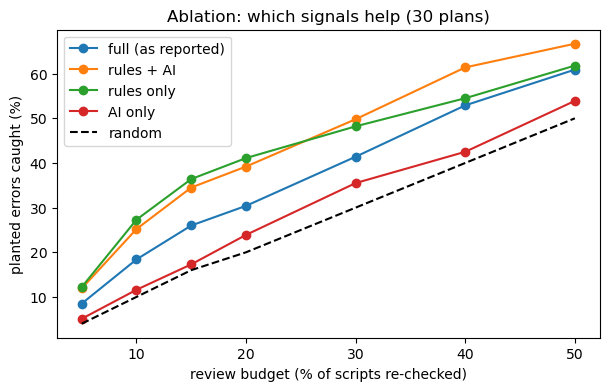

variant,AI only,full (as reported),rules + AI,rules only,random
budget,,,,,
0.05,0.051,0.085,0.119,0.122,0.04
0.10,0.116,0.184,0.252,0.273,0.10
0.15,0.173,0.260,0.345,0.364,0.16
0.20,0.239,0.304,0.392,0.411,0.20
0.30,0.355,0.414,0.498,0.482,0.30
0.40,0.425,0.529,0.614,0.545,0.40
0.50,0.539,0.609,0.667,0.618,0.50


In [21]:
VARIANTS = {
    "full (as reported)": {"strong": True, "page": True, "ai": True},
    "rules + AI": {"strong": True, "page": False, "ai": True},
    "rules only": {"strong": True, "page": False, "ai": False},
    "AI only": {"strong": False, "page": False, "ai": True},
}

def audit_variant(s, page_view, award, total, ai, use):
    score = 0.0
    if use["strong"]:
        for q in MAX_MARK:
            if award[q] > MAX_MARK[q]:
                score += W_STRONG
        if abs(sum(award.values()) - total) > 0.01:
            score += W_STRONG
    if use["page"]:
        for q in MAX_MARK:
            seen = page_view.get(q)
            if seen is not None and abs(seen - award[q]) > 0.01:
                score += W_FLAG
            if q in readings[s]["record"] and seen is None:
                score += W_FLAG
    if use["ai"]:
        for q in MAX_MARK:
            if ai[q] is not None:
                score += abs(ai[q] - min(award[q], MAX_MARK[q]))
    return score

ablation_rows = []
for plan_seed in range(100, 100 + N_PLANS):          # the SAME 30 plans as section 15c
    plan_i = make_error_plan(plan_seed)
    page_i, award_i, total_i = build_examiner_record(plan_i, plan_seed)
    seen_i = add_reading_noise(page_i, plan_seed)
    n_errors = sum(len(v) for v in plan_i.values())
    tie_rng = random.Random(plan_seed + 5)
    tie_break = {s: tie_rng.random() * 1e-6 for s in students_run}   # same random tie-break for every variant
    for name, use in VARIANTS.items():
        score = {s: audit_variant(s, seen_i[s], award_i[s], total_i[s], ai_mark[s], use) + tie_break[s]
                 for s in students_run}
        order = sorted(students_run, key=lambda s: score[s], reverse=True)
        for b in BUDGETS:
            k = max(1, round(b * len(order)))
            caught = sum(len(plan_i[s]) for s in order[:k])
            ablation_rows.append({"variant": name, "plan": plan_seed, "budget": b,
                                  "recall": caught / n_errors if n_errors else np.nan})

ablation = pd.DataFrame(ablation_rows)
ablation_table = ablation.pivot_table(index="budget", columns="variant", values="recall", aggfunc="mean").round(3)
ablation_table["random"] = [round(max(1, round(b * len(students_run))) / len(students_run), 3) for b in ablation_table.index]
ablation_table.to_csv(OUT_DIR / "ablation_30_plans.csv")

at_20 = ablation[ablation["budget"] == 0.20].groupby("variant")["recall"].agg(
    mean="mean", low=lambda x: np.percentile(x, 2.5), high=lambda x: np.percentile(x, 97.5)).round(3)
print("At a 20% review budget (30 plans):")
print(at_20)

fig, ax = plt.subplots(figsize=(7, 4))
for name in VARIANTS:
    ax.plot(ablation_table.index * 100, ablation_table[name] * 100, marker="o", label=name)
ax.plot(ablation_table.index * 100, ablation_table["random"] * 100, "k--", label="random")
ax.set_xlabel("review budget (% of scripts re-checked)"); ax.set_ylabel("planted errors caught (%)")
ax.set_title("Ablation: which signals help (30 plans)"); ax.legend(); plt.show()
ablation_table

## 16c. Ablation on the real-world pilot
Same switches, applied to the teacher's ORIGINAL records. Where do the three real cases land (out of 50)?
Rank is counted pessimistically: if several scripts have the same score, the case is placed at the bottom of that group.

In [22]:
def pilot_score(s, use):
    rec = recorded[s]
    record = readings[s]["record"]
    score = 0.0
    if use["strong"]:
        for q in SA_QUESTIONS:
            if rec["sa"][q] > MAX_MARK[q]:
                score += W_STRONG
        if abs(sum(rec["sa"].values()) - rec["sa_total"]) > 0.01:
            score += W_STRONG
        if abs(rec["mcq_total"] + rec["sa_total"] - rec["total"]) > 0.01:
            score += W_STRONG
    if use["page"]:
        ticks = sum(1 for q in MCQ_QUESTIONS if q in record and "tick" in record[q]["symbols"])
        if ticks and abs(ticks - rec["mcq_total"]) > 0.01:
            score += W_FLAG
    if use["ai"]:
        ai_mcq = sum(v for q, v in ai_mark[s].items() if q in MCQ_QUESTIONS and v is not None)
        score += abs(ai_mcq - rec["mcq_total"])
        for q in SA_QUESTIONS:
            if ai_mark[s][q] is not None:
                score += abs(ai_mark[s][q] - min(rec["sa"][q], 2))
    return score

REAL_CASES = {"Student_10": "correct MCQs crossed (~6 marks lost)",
              "Student_11": "Q34 counted twice (4/2)",
              "Student_12": "section total does not add up"}
pilot_rows = []
for name, use in VARIANTS.items():
    scores = {s: pilot_score(s, use) for s in students_run}
    for case, what in REAL_CASES.items():
        if case not in scores:
            continue
        rank = sum(1 for s in students_run if scores[s] >= scores[case])   # pessimistic rank
        pilot_rows.append({"variant": name, "case": case, "what": what, "rank_of_50": rank,
                           "caught_at_20pct": rank <= round(0.2 * len(students_run))})
ablation_pilot = pd.DataFrame(pilot_rows)
ablation_pilot.to_csv(OUT_DIR / "ablation_pilot.csv", index=False)
ablation_pilot.pivot(index="case", columns="variant", values="rank_of_50")

variant,AI only,full (as reported),rules + AI,rules only
case,,,,
Student_10,10,14,11,50
Student_11,5,1,1,2
Student_12,12,2,2,2


## 17. H2: what does the audit cost per script vs a human review?
Measured: seconds of GPU time per script. **Edit the assumptions** to your own numbers.
Human review cost reference: Punjab 2023 revision pays examiners about Rs 35–50 per paper.

In [23]:
GPU_WATTS = 180                 # assumption: power draw of the GPU while running (RTX 5060 Ti class)
ELECTRICITY_RS_PER_KWH = 60     # assumption: edit to your tariff
HARDWARE_COST_RS = 450000       # assumption: workstation price
HARDWARE_LIFE_HOURS = 3 * 365 * 8   # assumption: 3 years, 8 hours a day
HUMAN_REVIEW_RS = 35            # Punjab 2023 rate (lower end)

sec_per_script = float(np.median(list(seconds_per_script.values())))   # median: first scripts were distorted (D-017)
hours = sec_per_script / 3600
energy_rs = GPU_WATTS / 1000 * hours * ELECTRICITY_RS_PER_KWH
hardware_rs = HARDWARE_COST_RS / HARDWARE_LIFE_HOURS * hours
audit_rs = energy_rs + hardware_rs
print(f"Seconds per script (median, reading only): {sec_per_script:.0f}")
print(f"Audit cost per script: Rs {audit_rs:.2f}  (energy {energy_rs:.2f} + hardware {hardware_rs:.2f})")
print(f"Human re-check per script: Rs {HUMAN_REVIEW_RS}")
print(f"Scripts one GPU can audit per 8-hour day: {int(8 * 3600 / max(sec_per_script, 0.001))}")

Seconds per script (median, reading only): 48
Audit cost per script: Rs 0.83  (energy 0.14 + hardware 0.69)
Human re-check per script: Rs 35
Scripts one GPU can audit per 8-hour day: 599


## 18. Summary and limitations (write these into the report)
- **Data:** one public university exam (50 scripts, English). Not a Pakistani board exam.
- **Planted errors:** our error rates and types are assumptions; no board publishes real error rates.
- **Ground truth:** teacher marks + official key + verified fixes; 14 students uncertain (sensitivity reported).
- **Reading noise:** the page marks the audit sees get noise at the bake-off's measured error rate.
- **Circularity guard:** the error plan is random, fixed by a seed and saved before the audit; the audit never reads it.
- **AI never awards marks:** it only decides *where humans look first*.

In [24]:
summary = {
    "chosen_pipeline": CHOSEN_PIPELINE, "chosen_model": CHOSEN_MODEL,
    "red_read_error": RED_READ_ERROR,
    "h1_at_20pct_all": results_all[results_all["budget"] == 0.20].to_dict("records"),
    "h1_at_20pct_without_uncertain": results_certain[results_certain["budget"] == 0.20].to_dict("records"),
    "seconds_per_script": sec_per_script,
}
(OUT_DIR / "summary.json").write_text(json.dumps(summary, indent=1, default=str))
summary

{'chosen_pipeline': 'C',
 'chosen_model': 'qwen3-vl:8b-instruct',
 'red_read_error': 0.726,
 'h1_at_20pct_all': [{'set': 'all scripts',
   'budget': 0.2,
   'random_recall': 0.203,
   'random_95': (0.0, 0.46),
   'ranked_recall': 0.538,
   'ranked_95': (0.1, 0.62)}],
 'h1_at_20pct_without_uncertain': [{'set': 'without uncertain',
   'budget': 0.2,
   'random_recall': 0.186,
   'random_95': (0.0, 0.67),
   'ranked_recall': 0.667,
   'ranked_95': (0.0, 1.0)}],
 'seconds_per_script': 48.052653431892395}

In [25]:
print(len(readings), CHOSEN_PIPELINE, CHOSEN_MODEL, len(students_run))

50 C qwen3-vl:8b-instruct 50
